# Теория к лабораторной работе 4. Проверка статистических гипотез

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

seed = 0xC0FFEE
rng = np.random.default_rng(seed)

## Статистическая гипотеза

**Статистическая гипотеза** — это утверждение о параметрах распределения, из которого получена выборка. 

Гипотезой оно называется потому, что мы не знаем, верно ли оно.

Пример: выборка из нормального распределения $\mathcal{N}(\mu,\sigma^2)$ с неизвестным средним $\mu$ и известной дисперсией $\sigma^2$. 

$$
f(x)=\frac{1}{\sigma\sqrt{2\pi}}\,e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

Утверждения: 

- $\mu<1$
- $\mu=1$

это примеры статистических гипотез.


По выборке мы решаем одно из двух:

- гипотеза **принимается** — данные с ней согласуются;
- гипотеза **отвергается** — данные с ней плохо согласуются.


## Нулевая гипотеза. Простые и сложные гипотезы

Проверяемую гипотезу обозначают $H_0$ и называют **нулевой гипотезой**. 

Для выборки из $\mathcal{N}(\mu,1)$ возможны, например, такие нулевые гипотезы:
$$
\text{(a)}\ H_0\colon\mu=1,\qquad\qquad \text{(b)}\ H_0\colon\mu<1.
$$

- Гипотеза (a) полностью задает распределение: если она верна, то данные из $\mathcal{N}(1,1)$. Такая гипотеза называется **простой**.
- Гипотеза (b) распределение не задает: подходят и $\mathcal{N}(0,1)$, и $\mathcal{N}(-5,1)$. Такая гипотеза называется **сложной**.

Утверждение, которое мы противопоставляем $H_0$, называют **альтернативной гипотезой** $H_1$. Например, $H_1\colon\mu\ne1$.

## Ошибки I и II рода

Решение принимается по случайной выборке, поэтому оно может оказаться неверным. Возможны две ошибки:

| решение | $H_0$ верна | $H_0$ неверна |
|---|---|---|
| принимаем $H_0$ | верное решение | **ошибка II рода** |
| отвергаем $H_0$ | **ошибка I рода** | верное решение |

- **Ошибка I рода** — отвергнуть $H_0$, когда она верна («ложная тревога»). Ее вероятность обозначают $\alpha$ и называют **уровнем значимости** критерия. Обычно берут $\alpha=0.05$ или $\alpha=0.01$.
- **Ошибка II рода** — принять $H_0$, когда она неверна («пропуск»). Ее вероятность обозначают $\beta$. Она зависит от того, насколько истинное значение параметра отличается от разрешенного гипотезой $H_0$: большое отличие заметить легче.
- **Мощность** критерия $1-\beta$ — вероятность отвергнуть $H_0$, когда она неверна.

Пример: $H_0$ — «среднее время ответа сервиса не изменилось». Ошибка I рода — решить, что сервис стал медленнее, хотя ничего не изменилось. Ошибка II рода — не заметить реального замедления.

При фиксированном объеме выборки уменьшить обе ошибки сразу нельзя: чем строже порог для отвержения $H_0$, тем реже ложные тревоги, но тем чаще пропуски. Поэтому $\alpha$ фиксируют заранее, а $\beta$ уменьшают, увеличивая объем выборки $n$.

## Пример построения критерия

**Постановка.** $X_1,\dots,X_n$ — выборка из $\mathcal{N}(\mu,\sigma^2)$, среднее $\mu$ неизвестно, дисперсия $\sigma^2$ *известна*. Проверяем
$$
H_0\colon\mu=\mu_0\qquad\text{против}\qquad H_1\colon\mu\ne\mu_0,
$$
где $\mu_0$ — заданное число.

Оценка $\mu$ — выборочное среднее $\bar X_n$. 

Отвергаем $H_0$, если $\left|\bar X_n-\mu_0\right|>c$ для некоторого порога $c$.

Если $H_0$ верна, то $\bar X_n\sim\mathcal{N}(\mu_0,\,\sigma^2/n)$, и после стандартизации
$$
Z=\frac{\bar X_n-\mu_0}{\sigma/\sqrt n}\sim\mathcal{N}(0,1).
$$
Величину $Z$ называют **статистикой критерия**. Нужно, чтобы вероятность ошибки I рода была равна $\alpha$:
$$
\mathbb{P}\left(|Z|>z\right)=\alpha.
$$
Как и в лабораторной работе 3, в каждом «хвосте» должно остаться по $\alpha/2$, поэтому порог для $Z$ — квантиль $z_{1-\alpha/2}$. 

Возвращаясь к $\bar X_n$: 
$$c=z_{1-\alpha/2}\frac{\sigma}{\sqrt n}$$

**z-критерий уровня $\alpha$:**

- отвергнуть $H_0$, если 
$$
\left|\frac{\bar X_n-\mu_0}{\sigma/\sqrt n}\right|>z_{1-\alpha/2}
$$

- иначе принять $H_0$

Например, при $\sigma=1$, $\mu_0=1$, $\alpha=0.05$ гипотеза $H_0\colon\mu=1$ отвергается, если $|\bar X_n-1|>1.96/\sqrt n$.

На графике — плотность статистики $Z$ при верной $H_0$. Середина — **область принятия**, два «хвоста» — **критическая область**.

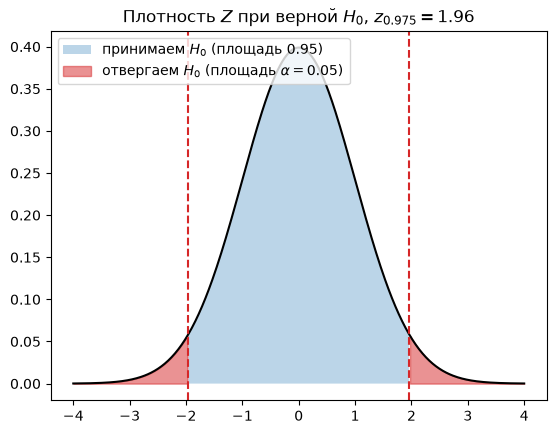

In [2]:
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)

grid = np.linspace(-4, 4, 400)
pdf = stats.norm.pdf(grid)
plt.plot(grid, pdf, color="black")

# область принятия: |Z| <= z_crit
inside = np.abs(grid) <= z_crit
plt.fill_between(grid[inside], pdf[inside], alpha=0.3, label=f"принимаем $H_0$ (площадь {1 - alpha:.2f})")

# критическая область: два хвоста, в каждом площадь alpha / 2
plt.fill_between(grid[grid > z_crit], pdf[grid > z_crit], color="C3", alpha=0.5,
                 label=rf"отвергаем $H_0$ (площадь $\alpha={alpha}$)")
plt.fill_between(grid[grid < -z_crit], pdf[grid < -z_crit], color="C3", alpha=0.5)

plt.axvline(-z_crit, color="C3", linestyle="--")
plt.axvline(z_crit, color="C3", linestyle="--")
plt.title(rf"Плотность $Z$ при верной $H_0$, $z_{{0.975}}={z_crit:.2f}$")
plt.legend(loc="upper left")
plt.show()

**Что означает $\alpha=0.05$ на практике.** Проверим моделированием. Пусть целевое среднее время ответа сервиса $\mu_0=200$ мс, стандартное отклонение известно: $\sigma=40$ мс, в каждом эксперименте $n=25$ замеров. Пусть $H_0$ *верна*: на самом деле $\mu=200$. Повторим эксперимент много раз и посмотрим, как часто z-критерий ошибочно отвергает $H_0$.

In [3]:
mu0, sigma, n = 200.0, 40.0, 25
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)

# M экспериментов, в каждом n замеров; H0 верна: mu = mu0
M = 100_000
X = rng.normal(loc=mu0, scale=sigma, size=(M, n))

# статистика критерия для каждого эксперимента
Z = (X.mean(axis=1) - mu0) / (sigma / np.sqrt(n))

# доля экспериментов, где H0 (верная!) отвергнута
reject = np.abs(Z) > z_crit
print(f"доля ошибок I рода: {reject.mean():.4f} (alpha = {alpha})")

доля ошибок I рода: 0.0498 (alpha = 0.05)


Примерно в 5% экспериментов критерий «поднимает тревогу», хотя ничего не изменилось. Это не дефект критерия, а его заданное свойство: вероятность ложной тревоги равна $\alpha$.